In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pickle
from tqdm import tqdm
from sklearn.utils import resample

plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'STIXGeneral'
%config InlineBackend.figure_formats = ['svg']

project_dir = os.path.expanduser('~/RL_2024/')

In [2]:
gamma = 1.0

In [3]:
nS = 750
nA = 25

nS_term = 2
S_survival = 750
S_death = 751

nS_total = nS + nS_term

In [4]:
with open(project_dir + 'data/env_model/gymP_orig.pkl', 'rb') as f:
    gymP_orig = pickle.load(f)
with open(project_dir + 'data/env_model/gymP_dropped.pkl', 'rb') as f:
    gymP_dropped = pickle.load(f)
with open(project_dir + 'data/env_model/gymP_shifted.pkl', 'rb') as f:
    gymP_shifted = pickle.load(f)

In [5]:
π_b_orig = pd.read_pickle(project_dir + 'data/behavior_policy/π_b_orig.pkl').values
π_b_dropped = pd.read_pickle(project_dir + 'data/behavior_policy/π_b_dropped.pkl').values
π_b_shifted = pd.read_pickle(project_dir + 'data/behavior_policy/π_b_shifted.pkl').values
SA_mask_orig = pd.read_pickle(project_dir + 'data/behavior_policy/SA_mask_orig.pkl').values
SA_mask_dropped = pd.read_pickle(project_dir + 'data/behavior_policy/SA_mask_dropped.pkl').values
SA_mask_shifted = pd.read_pickle(project_dir + 'data/behavior_policy/SA_mask_shifted.pkl').values

In [6]:
df_train_orig = pd.read_csv(project_dir + 'data/trajectory_data/traj_orig_train.csv', dtype={"a:action": "Int64", 'a:next_action': "Int64"})
df_test_orig = pd.read_csv(project_dir + 'data/trajectory_data/traj_orig_test.csv', dtype={"a:action": "Int64", 'a:next_action': "Int64"})

In [7]:
with open(project_dir + 'data/value_funcs/VI_orig__Vs.pkl', 'rb') as f:
    Vs_orig = pickle.load(f)

In [8]:
gymP = gymP_orig
π_b = π_b_orig
SA_mask = SA_mask_orig
df_train = df_train_orig
df_test = df_test_orig
Vs = Vs_orig

In [9]:
df_test

,traj,step,s:state,a:action,r:reward,s:next_state,a:next_action,done
0,13,0,486,0,0.0,585,0,0
1,13,1,585,0,0.0,374,0,0
2,13,2,374,0,0.0,374,10,0
3,13,3,374,10,0.0,699,15,0
4,13,4,699,15,0.0,699,5,0
...,...,...,...,...,...,...,...,...
38327,19626,8,645,0,0.0,645,0,0
38328,19626,9,645,0,0.0,645,0,0
38329,19626,10,645,0,0.0,513,0,0
38330,19626,11,513,0,0.0,513,0,0


In [10]:
df_test.groupby('traj')['r:reward'].sum().mean()

np.float64(0.8077445652173914)

In [11]:
# remove trajectories with no usable transitions
# (i.e., transitions with zero probability under the behavior policy)
trajectories = []
for i, traj in df_test.groupby('traj'):
    usable = True
    for t, transition in traj.iterrows():
        s = transition['s:state']
        a = transition['a:action']
        if np.isclose(π_b[s,a], 0.0):
            usable = False
            break
    if usable:
        trajectories.append(traj)

In [12]:
df_test['traj'].nunique(), len(trajectories)

(2944, 2510)

In [13]:
trajectories[0]

,traj,step,s:state,a:action,r:reward,s:next_state,a:next_action,done
0,13,0,486,0,0.0,585,0,0
1,13,1,585,0,0.0,374,0,0
2,13,2,374,0,0.0,374,10,0
3,13,3,374,10,0.0,699,15,0
4,13,4,699,15,0.0,699,5,0
5,13,5,699,5,0.0,480,5,0
6,13,6,480,5,0.0,480,5,0
7,13,7,480,5,0.0,221,5,0
8,13,8,221,5,0.0,486,5,0
9,13,9,486,5,0.0,486,5,0


In [14]:
# Observed test set returns
V_TEST = []
for i, traj in enumerate(trajectories):
    H = len(traj)
    G = 0
    for t in reversed(range(H)):
        G = traj.iloc[t]['r:reward'] + gamma * G
    V_TEST.append(G)
np.mean(V_TEST)

np.float64(0.8358565737051793)

In [ ]:
# # policy from value iteration with tie-breaking
# V = Vs[-1]
# Q = np.zeros((nS, nA))
# π_opt = np.zeros((nS, nA))
# for s in range(nS):
#     Q_s = np.zeros((nA))
#     for a in range(nA):
#         Q_s[a] = sum(p * (r + (0 if done else gamma * V[s_])) for p, s_, r, done in gymP[s][a])
#     Q[s, :] = Q_s  # save full Q-value matrix
#     Q_s[~SA_mask[s]] = np.nan  # mask out rare actions for constructing policy
#     max_val = np.nanmax(Q_s)
#     best_actions = np.where(Q_s == max_val)[0]
#     π_opt[s, best_actions] = 1 / len(best_actions)

In [85]:
def V2Q(V, gymP, gamma):
    Q = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            Q[s, a] = sum(p * (r + (0 if done else gamma * V[s_])) for p, s_, r, done in gymP[s][a])
    return Q  # save full Q-value matrix

def policy_eval(gymP, π, gamma, max_iter=None):
    V = np.zeros(nS)
    num_iter = 0
    while not max_iter or num_iter < max_iter:
        V_new = V.copy()
        for s in range(nS):
            ## V[s] = sum {a} π(a|s) sum {s', r} P[s', r | s, a] * (r + gamma * V[s'])
            Q_s = np.zeros(nA)
            for a in range(nA):
                Q_s[a] = sum(p * (r + (0 if done else gamma * V[s_])) for p, s_, r, done in gymP[s][a])
            V_new[s] = np.sum(π[s] * Q_s)
        if np.isclose(np.linalg.norm(V_new - V), 1e-10):
            break
        V = V_new
        num_iter += 1
    return V

In [17]:
V_opt = Vs[-1]
Q_opt = V2Q(V_opt, gymP, 0.99)

# mask out rare actions for constructing policy
Q_opt_masked = Q_opt.copy()
Q_opt_masked[~SA_mask] = np.nan

# policy from value iteration with tie-breaking
π_star = np.zeros((nS, nA))
for s in range(nS):
    Q_s = Q_opt_masked[s, :]
    max_val = np.nanmax(Q_s)
    best_actions = np.where(Q_s == max_val)[0]
    π_star[s, best_actions] = 1 / len(best_actions)

In [19]:
π_b.shape, π_star.shape

((750, 25), (750, 25))

In [88]:
V_star = policy_eval(gymP, π_star, gamma, max_iter=20)
Q_star = V2Q(V_star, gymP, gamma)

In [38]:
def IS(trajectories, π_e, π_b, clip_rho=None, clip_value=None):
    N = len(trajectories)
    G_list = []
    rho_list = []
    for traj in trajectories:
        G = traj['r:reward'].sum()
        prob_e = []
        prob_b = []
        for t, transition in traj.iterrows():
            s = transition['s:state']
            a = transition['a:action']
            prob_e.append(π_e[s,a])
            prob_b.append(π_b[s,a])
        prob_e = np.array(prob_e)
        prob_b = np.array(prob_b)
        rho = (prob_e / prob_b).prod()
        G_list.append(G)
        rho_list.append(rho)
    
    G_list = np.array(G_list)
    rho_list = np.array(rho_list)
    if clip_rho is not None:
        rho_list = np.clip(rho_list, clip_rho[0], clip_rho[1])
    
    V_IS_list = G_list * rho_list
    if clip_value is not None:
        V_IS_list = np.clip(V_IS_list, clip_value[0], clip_value[1])
    
    V_IS = np.sum(V_IS_list) / N
    return V_IS, {
        'V_IS': V_IS,
        'V_WIS': np.sum(G_list * rho_list) / np.sum(rho_list),
        'ESS_IS': np.sum(rho_list) ** 2 / np.sum(rho_list ** 2),
        'G_list': G_list,
        'rho_list': rho_list,
        'V_IS_list': G_list * rho_list,
        'V_WIS_list': G_list * rho_list / np.sum(rho_list) * N,
    }

## Evaluate π_b with IS

In [39]:
π_e = π_b.copy()

In [40]:
V_IS, IS_stats = IS(trajectories, π_e, π_b)
print('IS:', V_IS)
print('WIS:', IS_stats['V_WIS'])
print('ESS:', IS_stats['ESS_IS'])

IS: 0.8358565737051793
WIS: 0.8358565737051793
ESS: 2510.0


In [41]:
V_IS_b = []
for i in tqdm(range(1000)):
    V_IS_boot = resample(IS_stats['V_WIS_list'], replace=True, random_state=i)
    V_IS_b.append(np.mean(np.clip(V_IS_boot, -1, 1)))
V_IS_b = np.array(V_IS_b)
print(V_IS_b.mean(), V_IS_b.std())
print(np.median(V_IS_b))
print(np.percentile(V_IS_b, 2.5), np.percentile(V_IS_b, 97.5))

100%|███████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2096.60it/s]

0.8353848605577688 0.011193149941345144
0.8350597609561753
0.8135458167330677 0.856593625498008


In [42]:
# Soften policy to create evaluation policy
epsilon = 0.05
π_e = (1 - epsilon) * π_star + epsilon * π_b

In [43]:
V_IS, IS_stats = IS(trajectories, π_e, π_b, clip_rho=(1e-3, 1e3), clip_value=None)
print('IS:', V_IS)
print('WIS:', IS_stats['V_WIS'])
print('ESS:', IS_stats['ESS_IS'])

IS: 10.267355874834118
WIS: 0.8625894553382218
ESS: 34.8080908930647


In [44]:
V_WIS_b = []
for i in tqdm(range(1000)):
    G_list_boot, rho_list_boot = resample(IS_stats['G_list'], IS_stats['rho_list'], replace=True, random_state=i)
    V_WIS_boot = np.sum(G_list_boot * rho_list_boot) / np.sum(rho_list_boot),
    V_WIS_b.append(V_WIS_boot)
V_WIS_b = np.array(V_WIS_b)
print(V_WIS_b.mean(), V_WIS_b.std())
print(np.median(V_WIS_b))
print(np.percentile(V_WIS_b, 2.5), np.percentile(V_WIS_b, 97.5))

100%|███████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2071.94it/s]

0.8618454343050767 0.09281189456661992
0.8671077754272862
0.6492640239764731 0.997724640987403


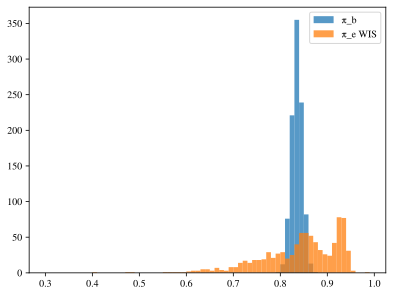

In [45]:
plt.hist(V_IS_b, alpha=0.75, bins=np.arange(0.3, 1.0, 0.01), label='π_b')
plt.hist(V_WIS_b, alpha=0.75, bins=np.arange(0.3, 1.0, 0.01), label='π_e WIS')
plt.legend()
plt.show()

## OSIRIS

In [45]:
Q_mintomax = np.nanmax(Q, axis=1) - np.nanmin(Q, axis=1)

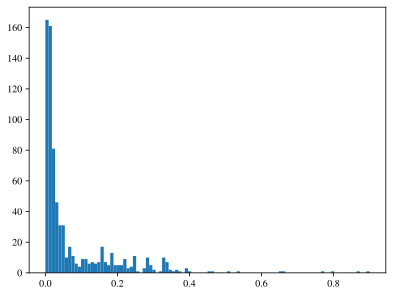

In [47]:
plt.hist(Q_mintomax, bins=100)
plt.show()

In [96]:
epsilon = 0.95
value_threshold = 0.1

epsilon = 0.95
value_threshold = 0.05

relevent_states = np.where(Q_mintomax > 0.4)[0]
print('Number of relevant states:', len(relevent_states))

π_e = π_opt.copy()
π_e[Q_mintomax < value_threshold] = π_b[Q_mintomax < value_threshold]
π_e = (1 - epsilon) * π_e + epsilon * π_b

Number of relevant states: 11


In [ ]:
# IS estimator
output = []
for i, traj in tqdm(enumerate(trajectories), total=len(trajectories)):
    G, rho = IS(traj, π_e)
    output.append((i, G, rho))

_, G_list, weights = zip(*output)
G_list = np.array(G_list)
weights = np.array(weights)
N = len(G_list)
V_IS_list = G_list * weights
V_IS = np.average(G_list * weights)
V_WIS = np.average(G_list, weights=weights)
ESS_IS = N * (weights.mean() ** 2) / (weights ** 2).mean()
print('IS:', V_IS)
print('WIS:', V_WIS)
print('ESS:', ESS_IS)

100%|████████████████████████████████████████████████████████████████████████████| 2510/2510 [00:02<00:00, 962.47it/s]

IS: 0.8813053271411463
WIS: 0.8522074045866956
ESS: 1770.9383433075993


## Per Traj DR

In [61]:
def per_trajectory_WDR(trajectories, π_e, π_b, Q_hat, V_hat, clip_rho=None, clip_value=None):
    N = len(trajectories)
    G_list = []
    rho_list = []
    for traj in trajectories:
        G = traj['r:reward'].sum()
        prob_e = []
        prob_b = []
        for t, transition in traj.iterrows():
            s = transition['s:state']
            a = transition['a:action']
            prob_e.append(π_e[s,a])
            prob_b.append(π_b[s,a])
        prob_e = np.array(prob_e)
        prob_b = np.array(prob_b)
        rho = (prob_e / prob_b).prod()
        G_list.append(G)
        rho_list.append(rho)
    
    G_list = np.array(G_list)
    rho_list = np.array(rho_list)
    if clip_rho is not None:
        rho_list = np.clip(rho_list, clip_rho[0], clip_rho[1])
    
    V_IS_list = []
    for i, traj in enumerate(trajectories):
        s_init = int(traj.iloc[0]['s:state'])
        a_init = int(traj.iloc[0]['a:action'])
        V_IS_i = V_hat[s_init] + rho_list[i] * (G_list[i] - Q_hat[s_init, a_init])
        # V_IS_i = V_hat[s_init]
        # V_IS_i = rho_list[i] * G_list[i]
        V_IS_list.append(V_IS_i)
    V_IS_list = np.array(V_IS_list)

    if clip_value is not None:
        V_IS_list = np.clip(V_IS_list, clip_value[0], clip_value[1])
    
    V_IS = np.sum(V_IS_list) / N
    return V_IS, {
        'V_list': V_IS_list,
        'G_list': G_list,
        'rho_list': rho_list,
    }

In [62]:
# Soften policy to create evaluation policy
epsilon = 0.05
π_e = (1 - epsilon) * π_star + epsilon * π_b

In [63]:
# V_DR, DR_stats = per_trajectory_WDR(trajectories, π_e, π_b, np.zeros_like(Q_opt), np.zeros_like(V_opt), clip_rho=(1e-3, 1e3), clip_value=None)
V_DR, DR_stats = per_trajectory_WDR(trajectories, π_e, π_b, Q_star, V_star, clip_rho=(1e-3, 1e3), clip_value=None)
V_WDR = np.sum(DR_stats['V_list']) / np.sum(DR_stats['rho_list'])
print(V_DR, V_WDR)

-0.6022963184469352 -0.050600608337222144


In [65]:
DR_stats['rho_list'].mean()

np.float64(11.902946194500235)

In [ ]:
V_WDR_b = []
for i in tqdm(range(1000)):
    V_list_boot, rho_list_boot = resample(DR_stats['V_list'], DR_stats['rho_list'], replace=True, random_state=i)
    V_WDR_boot = np.sum(V_list_boot) / np.sum(rho_list_boot)
    V_WDR_b.append(V_WDR_boot)
V_WDR_b = np.array(V_WDR_b)
print(V_WDR_b.mean(), V_WDR_b.std())
print(np.median(V_WDR_b))
print(np.percentile(V_WDR_b, 2.5), np.percentile(V_WDR_b, 97.5))

## Per Decision DR

In [75]:
def perdecision_DR(trajectories, π_e, π_b, Q_hat, V_hat, clip_rho=None, clip_value=None):
    N = len(trajectories)
    G_list = []
    for i, traj in enumerate(trajectories):
        G = 0
        for t in reversed(range(len(traj))):
            transition = traj.iloc[t]
            s = int(transition['s:state'])
            a = int(transition['a:action'])
            r = transition['r:reward']
            done = transition['done']
            rho = π_e[s, a] / π_b[s, a]
            if clip_rho is not None:
                rho = np.clip(rho, clip_rho[0], clip_rho[1])
            if done:
                G = V_hat[s] + rho * (r - Q_hat[s, a])
            else:
                G = V_hat[s] + rho * (r + gamma * G - Q_hat[s, a])
        
        G_list.append(G)

    G_list = np.array(G_list)
    if clip_value is not None:
        G_list = np.clip(G_list, clip_value[0], clip_value[1])

    V_DR = np.sum(G_list) / N
    return V_DR, {
        'V_DR': V_DR,
        'G_list': G_list,
    }

In [ ]:
def V_WDR():
    N = len(trajectories)
    maxH = max(len(df_traj) for df_traj in trajectories)

    # # Calculate all per-step importance sampling ratios
    # perstep_rho = np.ones((N, maxH))
    # for i, traj in enumerate(trajectories):
    #     for t, transition in traj.iterrows():
    #         s = transition['s:state']
    #         a = transition['a:action']
    #         perstep_rho[i, t] = π_e[s,a] / π_b[s,a]
    
    # # Calculate cumulative importance ratio, rho_{1:t} for each trajectory at each step
    # cumulative_rho = np.cumprod(perstep_rho, axis=1)

    # # Calculate the average cumulative importance ratio at every horizon t
    # weights = cumulative_rho.mean(axis=0)


In [92]:
π_e = π_b.copy()

In [93]:
V_DR, DR_stats = PDWDR(trajectories, π_e, π_b, np.zeros_like(Q_star), np.zeros_like(V_star))
print(V_DR)

0.8358565737051793


In [94]:
V_DR, DR_stats = PDWDR(trajectories, π_e, π_b, Q_star, V_star, clip_value=(-1, 1))
print(V_DR)

0.8562439736051501


In [95]:
# Soften policy to create evaluation policy
epsilon = 0.05
π_e = (1 - epsilon) * π_star + epsilon * π_b

In [96]:
V_DR, DR_stats = perdecision_DR(trajectories, π_e, π_b, Q_star, V_star, clip_value=(-1, 1))
print(V_DR)

0.8651201675314636


In [97]:
V_DR_b = []
for i in tqdm(range(1000)):
    G_list_boot = resample(DR_stats['G_list'], replace=True, random_state=i)
    V_DR_boot = np.sum(G_list_boot) / len(trajectories)
    V_DR_b.append(V_DR_boot)
V_DR_b = np.array(V_DR_b)
print(V_DR_b.mean(), V_DR_b.std())
print(np.median(V_DR_b))
print(np.percentile(V_DR_b, 2.5), np.percentile(V_DR_b, 97.5))

100%|███████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2193.38it/s]

0.864864199910016 0.006790935566559398
0.8649143341926575
0.8512078865807413 0.8777677924942787


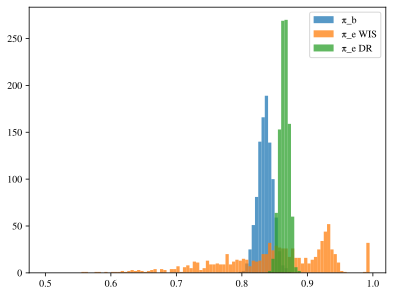

In [101]:
plt.hist(V_IS_b, alpha=0.75, bins=np.arange(0.5, 1.0, 0.005), label='π_b')
plt.hist(V_WIS_b, alpha=0.75, bins=np.arange(0.5, 1.0, 0.005), label='π_e WIS')
plt.hist(V_DR_b, alpha=0.75, bins=np.arange(0.5, 1.0, 0.005), label='π_e DR')
plt.legend()
plt.show()